# Insurance Claim Fraud Detection and Risk Analysis System
**ML Notebook (Beginner Version)** – Dataset: `fraud_oracle.csv` (Kaggle: Vehicle Insurance Claim Fraud Detection)

**Goal:** predict whether a claim is **Genuine (0)** or **Fraudulent (1)** using 4 models:
Logistic Regression, KNN, Random Forest, SVM.

**Before running:** upload `fraud_oracle.csv` using the folder icon on the left side of Colab.
Then run the cells one by one from top to bottom (Runtime → Run all also works).

## Step 1: Import Libraries
- `pandas` – loads and handles table data (like Excel in Python)
- `numpy` – maths on numbers
- `matplotlib` – draws graphs
- `seaborn` – nicer graphs built on matplotlib

**Viva:** *Pandas loads and manipulates the dataset, NumPy handles numerical operations, Matplotlib and Seaborn create visualizations.*

In [1]:
# Step 1: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ModuleNotFoundError: No module named 'pandas'

## Step 2: Load Dataset
`pd.read_csv()` reads the CSV file into a **DataFrame** (a table with rows = claims, columns = features).
- `df.head()` – first 5 rows
- `df.shape` – (rows, columns)
- `df.info()` – column names, data types, non-empty counts
- `df.describe()` – statistics (mean, min, max) of numeric columns

**Expected:** 15,420 rows and 33 columns. 9 numeric columns, 24 text (categorical) columns. Target = `FraudFound_P` (0 = Genuine, 1 = Fraud).

In [ ]:
# Step 2: Load Dataset
df = pd.read_csv("fraud_oracle.csv")
df.head()

,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


In [ ]:
df.shape

(15420, 33)

In [ ]:
df.size

508860

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Month                 15420 non-null  object
 1   WeekOfMonth           15420 non-null  int64 
 2   DayOfWeek             15420 non-null  object
 3   Make                  15420 non-null  object
 4   AccidentArea          15420 non-null  object
 5   DayOfWeekClaimed      15420 non-null  object
 6   MonthClaimed          15420 non-null  object
 7   WeekOfMonthClaimed    15420 non-null  int64 
 8   Sex                   15420 non-null  object
 9   MaritalStatus         15420 non-null  object
 10  Age                   15420 non-null  int64 
 11  Fault                 15420 non-null  object
 12  PolicyType            15420 non-null  object
 13  VehicleCategory       15420 non-null  object
 14  VehiclePrice          15420 non-null  object
 15  FraudFound_P          15420 non-null

In [ ]:
df.describe()

,WeekOfMonth,WeekOfMonthClaimed,Age,FraudFound_P,PolicyNumber,RepNumber,Deductible,DriverRating,Year
count,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000
mean,2.788586,2.693969,39.855707,0.059857,7710.500000,8.483268,407.704280,2.487808,1994.866472
std,1.287585,1.259115,13.492377,0.237230,4451.514911,4.599948,43.950998,1.119453,0.803313
min,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,300.000000,1.000000,1994.000000
25%,2.000000,2.000000,31.000000,0.000000,3855.750000,5.000000,400.000000,1.000000,1994.000000
50%,3.000000,3.000000,38.000000,0.000000,7710.500000,8.000000,400.000000,2.000000,1995.000000
75%,4.000000,4.000000,48.000000,0.000000,11565.250000,12.000000,400.000000,3.000000,1996.000000
max,5.000000,5.000000,80.000000,1.000000,15420.000000,16.000000,700.000000,4.000000,1996.000000


## Step 3: Understand the Dataset
- `df.columns` – list of column names
- `df.isnull().sum()` – number of missing values in each column
- `df.duplicated().sum()` – number of duplicate rows
- `value_counts()` – how many times each value appears

**Imbalanced data problem:** only ~6% of claims are fraud. A lazy model that says "Genuine" for everything gets ~94% accuracy
but catches **zero** frauds. So accuracy alone is misleading here.

**Viva:** *The dataset is imbalanced: about 94% genuine and 6% fraud. A model can get high accuracy just by predicting the majority class.*

In [ ]:
# Step 3: Understand Dataset
df.columns

Index(['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea',
       'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex',
       'MaritalStatus', 'Age', 'Fault', 'PolicyType', 'VehicleCategory',
       'VehiclePrice', 'FraudFound_P', 'PolicyNumber', 'RepNumber',
       'Deductible', 'DriverRating', 'Days_Policy_Accident',
       'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle',
       'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType',
       'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'Year',
       'BasePolicy'],
      dtype='object')

In [ ]:
for col in df.columns:
    print(f"\nColumn: {col}")
    print(df[col].unique())


Column: Month
['Dec' 'Jan' 'Oct' 'Jun' 'Feb' 'Nov' 'Apr' 'Mar' 'Aug' 'Jul' 'May' 'Sep']

Column: WeekOfMonth
[5 3 2 4 1]

Column: DayOfWeek
['Wednesday' 'Friday' 'Saturday' 'Monday' 'Tuesday' 'Sunday' 'Thursday']

Column: Make
['Honda' 'Toyota' 'Ford' 'Mazda' 'Chevrolet' 'Pontiac' 'Accura' 'Dodge'
 'Mercury' 'Jaguar' 'Nisson' 'VW' 'Saab' 'Saturn' 'Porche' 'BMW' 'Mecedes'
 'Ferrari' 'Lexus']

Column: AccidentArea
['Urban' 'Rural']

Column: DayOfWeekClaimed
['Tuesday' 'Monday' 'Thursday' 'Friday' 'Wednesday' 'Saturday' 'Sunday']

Column: MonthClaimed
['Jan' 'Nov' 'Jul' 'Feb' 'Mar' 'Dec' 'Apr' 'Aug' 'May' 'Jun' 'Sep' 'Oct']

Column: WeekOfMonthClaimed
[1 4 2 3 5]

Column: Sex
['Female' 'Male']

Column: MaritalStatus
['Single' 'Married' 'Widow' 'Divorced']

Column: Age
[21 34 47 65 27 20 36  0 30 42 71 52 28 61 38 41 32 40 63 31 45 60 39 55
 35 44 72 29 37 59 49 50 26 48 64 33 74 23 25 56 16 68 18 51 22 53 46 43
 57 54 69 67 19 78 77 75 80 58 73 24 76 62 79 70 17 66]

Column: Fault
['Poli

In [ ]:
df.isnull().sum()

,0
Month,0
WeekOfMonth,0
DayOfWeek,0
Make,0
AccidentArea,0
DayOfWeekClaimed,0
MonthClaimed,0
WeekOfMonthClaimed,0
Sex,0
MaritalStatus,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["FraudFound_P"].value_counts()

,count
FraudFound_P,
0,14497
1,923


In [ ]:
genuine = (df["FraudFound_P"] == 0).sum()
fraud = (df["FraudFound_P"] == 1).sum()

print("Genuine claims:", genuine)
print("Fraud claims:", fraud)
print("Genuine percentage:", round(genuine / len(df) * 100, 2), "%")
print("Fraud percentage:", round(fraud / len(df) * 100, 2), "%")

Genuine claims: 14497
Fraud claims: 923
Genuine percentage: 94.01 %
Fraud percentage: 5.99 %


## Step 4: Exploratory Data Analysis (EDA)
EDA means looking at the data with graphs **before** building models, to find patterns.
For each graph below: X-axis = the category/value, Y-axis = number of claims, colour = Genuine (0) or Fraud (1).
Because genuine claims are far more numerous, the fraud bars look small, so after each graph we also print the **fraud percentage inside each group**.
That percentage is the useful number.

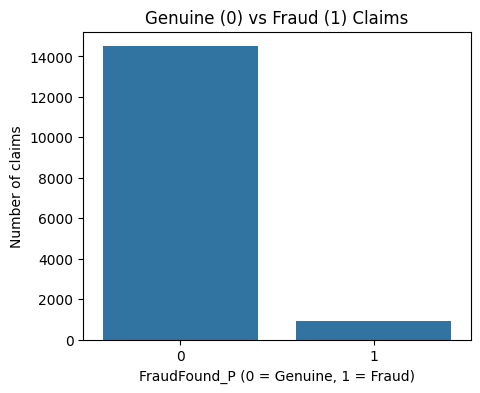

In [ ]:
# Step 4: EDA
# Graph 1: Fraud vs Genuine claims
plt.figure(figsize=(5, 4))
sns.countplot(x="FraudFound_P", data=df)
plt.title("Genuine (0) vs Fraud (1) Claims")
plt.xlabel("FraudFound_P (0 = Genuine, 1 = Fraud)")
plt.ylabel("Number of claims")
plt.show()

**Graph 1:** X = claim type, Y = number of claims. The genuine bar is huge compared to the fraud bar → the data is imbalanced.

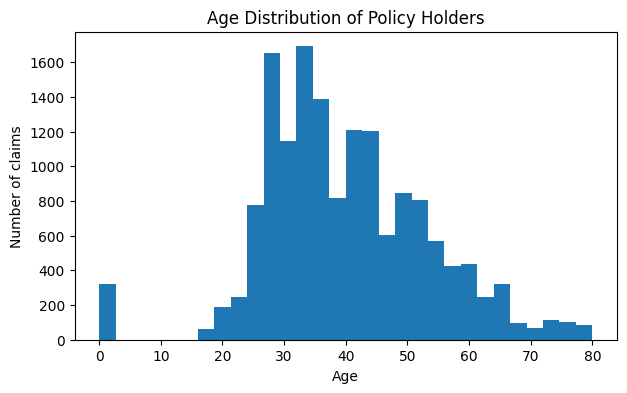

Claims with Age = 0: 320


In [ ]:
# Graph 2: Age distribution
plt.figure(figsize=(7, 4))
plt.hist(df["Age"], bins=30)
plt.title("Age Distribution of Policy Holders")
plt.xlabel("Age")
plt.ylabel("Number of claims")
plt.show()

print("Claims with Age = 0:", (df["Age"] == 0).sum())

**Graph 2:** X = age, Y = number of claims. Most policy holders are 25–55. The spike at 0 means 'age not recorded' (320 claims).

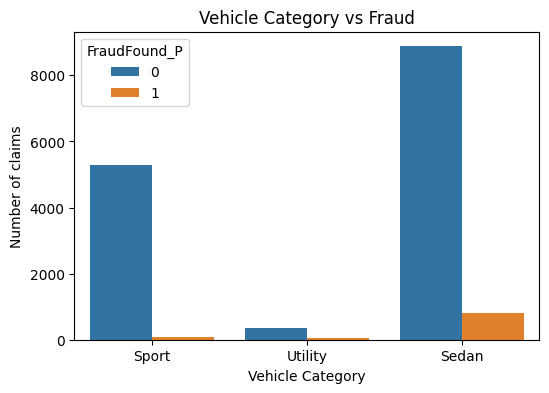

VehicleCategory
Sedan       8.220453
Sport       1.567749
Utility    11.253197
Name: FraudFound_P, dtype: float64


In [ ]:
# Graph 3: Vehicle category vs fraud
plt.figure(figsize=(6, 4))
sns.countplot(x="VehicleCategory", hue="FraudFound_P", data=df)
plt.title("Vehicle Category vs Fraud")
plt.xlabel("Vehicle Category")
plt.ylabel("Number of claims")
plt.show()

print(df.groupby("VehicleCategory")["FraudFound_P"].mean() * 100)

**Graph 3:** X = vehicle category, Y = number of claims. The printed numbers show the % of claims in each category that are fraud.

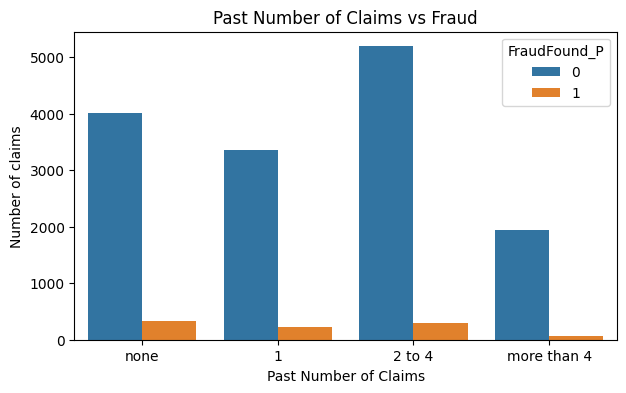

PastNumberOfClaims
1              6.213266
2 to 4         5.360073
more than 4    3.383085
none           7.789522
Name: FraudFound_P, dtype: float64


In [ ]:
# Graph 4: Past number of claims vs fraud
plt.figure(figsize=(7, 4))
sns.countplot(x="PastNumberOfClaims", hue="FraudFound_P", data=df,
              order=["none", "1", "2 to 4", "more than 4"])
plt.title("Past Number of Claims vs Fraud")
plt.xlabel("Past Number of Claims")
plt.ylabel("Number of claims")
plt.show()

print(df.groupby("PastNumberOfClaims")["FraudFound_P"].mean() * 100)

**Graph 4:** X = how many claims the person made before, Y = number of claims. Compare the fraud % across groups to see if past claims matter.

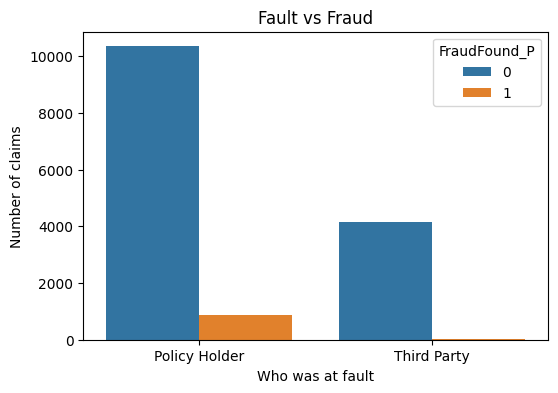

Fault
Policy Holder    7.889581
Third Party      0.883055
Name: FraudFound_P, dtype: float64


In [ ]:
# Graph 5: Fault vs fraud
plt.figure(figsize=(6, 4))
sns.countplot(x="Fault", hue="FraudFound_P", data=df)
plt.title("Fault vs Fraud")
plt.xlabel("Who was at fault")
plt.ylabel("Number of claims")
plt.show()

print(df.groupby("Fault")["FraudFound_P"].mean() * 100)

**Graph 5:** X = who was at fault (policy holder or third party), Y = number of claims. A big difference in fraud % means `Fault` is a useful clue.

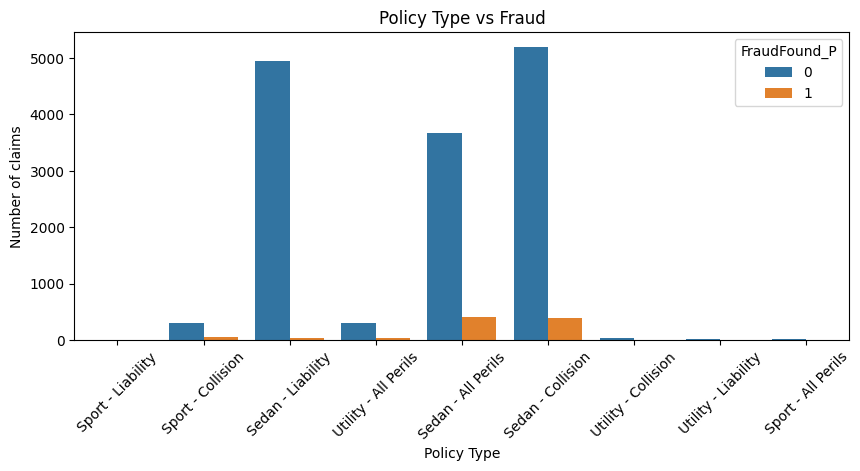

PolicyType
Sedan - All Perils      10.056276
Sedan - Collision        6.876791
Sedan - Liability        0.721877
Sport - All Perils       0.000000
Sport - Collision       13.793103
Sport - Liability        0.000000
Utility - All Perils    12.058824
Utility - Collision     10.000000
Utility - Liability      0.000000
Name: FraudFound_P, dtype: float64


In [ ]:
# Graph 6: Policy type vs fraud
plt.figure(figsize=(10, 4))
sns.countplot(x="PolicyType", hue="FraudFound_P", data=df)
plt.title("Policy Type vs Fraud")
plt.xlabel("Policy Type")
plt.ylabel("Number of claims")
plt.xticks(rotation=45)
plt.show()

print(df.groupby("PolicyType")["FraudFound_P"].mean() * 100)

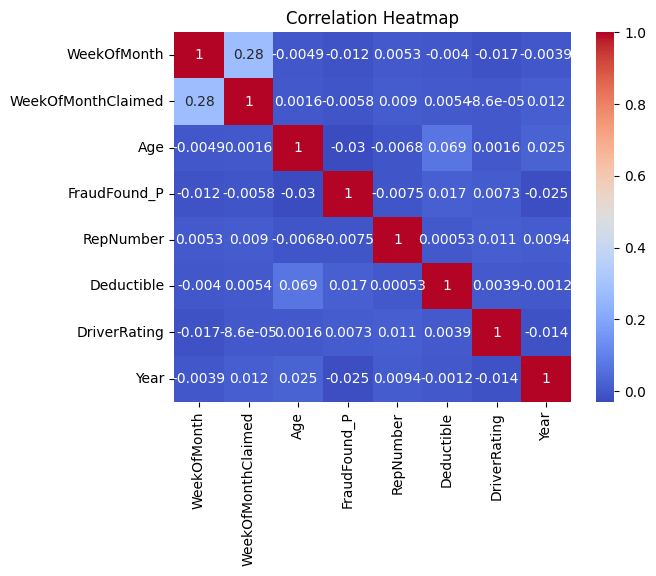

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


**Graph 6:** X = policy type, Y = number of claims. Some policy types have a noticeably higher fraud %.

**Why EDA helps fraud detection:** it shows which features separate fraud from genuine claims, so we understand what the models will pick up on.

## Step 5: Data Preprocessing
Models only understand numbers, so we must clean the data and convert text to numbers.

1. **Drop `PolicyNumber`** – it is just a claim ID, not a real feature.
2. **Remove 1 bad row** – one row has `0` as a placeholder in `MonthClaimed`/`DayOfWeekClaimed`.
3. **One-Hot Encoding** with `pd.get_dummies()` – makes a separate 0/1 column for each category
   (e.g. `PoliceReportFiled_Yes`). We use it instead of label encoding because most categories have no natural order.
   `drop_first=True` removes one redundant column per feature (if `Sex_Male = 0`, the person must be Female).
4. **Scaling** is done *after* the train/test split to avoid data leakage (see Step 6).

**Data leakage** = the model secretly sees information from the test data. Example: giving students the exam paper in advance.
Things that *learn from data* (StandardScaler, SMOTE) must be fitted on **training data only**.

In [ ]:
# Step 5: Data Preprocessing

# 5.1 Remove ID column and the one bad row
df = df.drop("PolicyNumber", axis=1)
df = df[df["MonthClaimed"] != "0"]
print("Shape after cleaning:", df.shape)

Shape after cleaning: (15419, 32)


In [ ]:
# 5.2 Find numerical and categorical columns
numerical_columns = df.select_dtypes(include="number").columns.tolist()
numerical_columns.remove("FraudFound_P")      # target is not an input feature

categorical_columns = df.select_dtypes(exclude="number").columns.tolist()

print("Numerical columns:", len(numerical_columns))
print(numerical_columns)
print()
print("Categorical columns:", len(categorical_columns))
print(categorical_columns)

Numerical columns: 7
['WeekOfMonth', 'WeekOfMonthClaimed', 'Age', 'RepNumber', 'Deductible', 'DriverRating', 'Year']

Categorical columns: 24
['Month', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'Sex', 'MaritalStatus', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'BasePolicy']


In [ ]:
# 5.3 One-Hot Encoding
df_encoded = pd.get_dummies(df, columns=categorical_columns, drop_first=True, dtype=int)

print("Shape after encoding:", df_encoded.shape)
df_encoded.head()

Shape after encoding: (15419, 121)


,WeekOfMonth,WeekOfMonthClaimed,Age,FraudFound_P,RepNumber,Deductible,DriverRating,Year,Month_Aug,Month_Dec,...,AddressChange_Claim_2 to 3 years,AddressChange_Claim_4 to 8 years,AddressChange_Claim_no change,AddressChange_Claim_under 6 months,NumberOfCars_2 vehicles,NumberOfCars_3 to 4,NumberOfCars_5 to 8,NumberOfCars_more than 8,BasePolicy_Collision,BasePolicy_Liability
0,5,1,21,0,12,300,1,1994,0,1,...,0,0,0,0,0,1,0,0,0,1
1,3,4,34,0,15,400,4,1994,0,0,...,0,0,1,0,0,0,0,0,1,0
2,5,2,47,0,7,400,3,1994,0,0,...,0,0,1,0,0,0,0,0,1,0
3,2,1,65,0,4,400,2,1994,0,0,...,0,0,1,0,0,0,0,0,0,1
4,5,2,27,0,3,400,1,1994,0,0,...,0,0,1,0,0,0,0,0,1,0


In [ ]:
# 5.4 Check: no missing values, all numbers
print("Missing values:", df_encoded.isnull().sum().sum())
print(df_encoded["FraudFound_P"].value_counts())

Missing values: 0
FraudFound_P
0    14496
1      923
Name: count, dtype: int64


## Step 6: Train/Test Split
- **X** = input features (all columns except the target)
- **y** = the answer we want to predict (`FraudFound_P`)
- `train_test_split` splits the data into:
  - `X_train`, `y_train` – **training data** (the model learns from these, 80%)
  - `X_test`, `y_test` – **testing data** (kept hidden to check the model honestly, 20%)
- `test_size=0.2` → 20% for testing
- `random_state=42` → same split every time we run (reproducible)
- `stratify=y` → keeps the same fraud percentage (~6%) in both train and test. Without it, a random split could give very few frauds in the test set.

**Why not train on test data?** It's like studying from the exam paper: you would score high without really learning, and the score would not be trustworthy.

**Viva:** *We split the data so the model is evaluated on claims it has never seen. This tells us how it will behave on new claims.*

In [ ]:
# Step 6: Train/Test Split
from sklearn.model_selection import train_test_split

X = df_encoded.drop("FraudFound_P", axis=1)
y = df_encoded["FraudFound_P"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print()
print("Fraud % in train:", round(y_train.mean() * 100, 2))
print("Fraud % in test:", round(y_test.mean() * 100, 2))

X shape: (15419, 120)
y shape: (15419,)
X_train: (12335, 120)
X_test: (3084, 120)

Fraud % in train: 5.98
Fraud % in test: 6.0


### Step 6B: Feature Scaling (after the split)
**Problem:** columns have different ranges (`Age` 0–80, `Deductible` ~400–700, dummy columns 0/1).
KNN and SVM use **distances**, so big-number columns would dominate.

**StandardScaler** changes each column using: `(value - mean) / standard deviation` → mean 0, spread 1.

- `scaler.fit_transform(X_train)` → **learns** the mean and std from the **training data only**, then scales it
- `scaler.transform(X_test)` → scales the test data using the **training** mean/std (no learning from test = no leakage)

Note: after scaling, the data becomes a NumPy array (the column names disappear). That is normal.

In [ ]:
# Step 6B: Feature Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # learn from train + scale train
X_test_scaled = scaler.transform(X_test)         # only scale test (no learning)

print("Train mean of first 3 columns (should be ~0):", X_train_scaled[:, :3].mean(axis=0).round(2))
print("Scaled train shape:", X_train_scaled.shape)

Train mean of first 3 columns (should be ~0): [-0. -0.  0.]
Scaled train shape: (12335, 120)


## Step 7: Handle Imbalanced Data (SMOTE)
**Problem:** only ~6% fraud, so models tend to ignore fraud.

**SMOTE** (Synthetic Minority Over-sampling Technique) creates **new, artificial fraud examples**.
It does *not* just copy existing frauds: it picks a fraud claim, finds similar fraud claims nearby, and creates a new point **between** them.

Rules:
- Apply SMOTE **only on training data** (never on test data, otherwise test would contain fake claims → leakage).
- The test set stays untouched with its real ~6% fraud.

`fit_resample(X, y)` = learn the fraud neighbourhoods and return the balanced dataset.

Small note: SMOTE can create fractional values in 0/1 columns. For this practical level that is acceptable.

In [ ]:
# Step 7: Handle Imbalanced Data
from imblearn.over_sampling import SMOTE

print("Before SMOTE")
print("Genuine:", (y_train == 0).sum())
print("Fraud:", (y_train == 1).sum())

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print()
print("After SMOTE")
print("Genuine:", (y_train_smote == 0).sum())
print("Fraud:", (y_train_smote == 1).sum())

Before SMOTE
Genuine: 11597
Fraud: 738

After SMOTE
Genuine: 11597
Fraud: 11597


We now have 3 sets of data:
- `X_train_smote, y_train_smote` → used to **train** the models
- `X_test_scaled, y_test` → used to **test** the models (real, untouched)

## Step 8: Logistic Regression
Despite the name, it is a **classification** model. It calculates a score from the features and converts it into a
**probability between 0 and 1** (using the S-shaped sigmoid curve). If the probability of fraud is above 0.5 → predict Fraud.

- `LogisticRegression(max_iter=1000)` – creates the model (`max_iter` = how many tries it gets to learn; 1000 avoids a warning)
- `model.fit(X_train, y_train)` – **training**: the model learns patterns from the examples
- `model.predict(X_test)` – gives the predicted class (0 or 1)
- `model.predict_proba(X_test)` – gives probabilities: column 0 = Genuine, column 1 = Fraud

In [ ]:
# Step 8: Logistic Regression
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=1000)

model_lr.fit(X_train_smote, y_train_smote)

y_pred_lr = model_lr.predict(X_test_scaled)
y_prob_lr = model_lr.predict_proba(X_test_scaled)[:, 1]    # probability of Fraud

print("First 10 predictions:", y_pred_lr[:10])
print("First 5 fraud probabilities:", y_prob_lr[:5].round(3))

First 10 predictions: [0 0 0 0 1 0 1 1 1 0]
First 5 fraud probabilities: [0.039 0.026 0.067 0.056 0.544]


## Step 9: KNN (K-Nearest Neighbours)
Idea: *"You are like your neighbours."* To judge a new claim, KNN finds the **K most similar claims** in the training data
and takes a **majority vote** of their labels.

- **K** = how many neighbours vote. K = 5 → look at the 5 closest claims.
- **Distance** = how far apart two claims are (computed from all feature values).
- **Scaling matters:** without it, a column with big numbers would dominate the distance. We already scaled.

We try K = 3, 5, 7, 9, 11 and compare. Because of the imbalance, we compare **F1-score and recall** (not just accuracy).

*Honest note for viva:* here we choose K by looking at test results. In a larger project we would use a separate validation set.
This keeps the practical simple.

In [ ]:
# Step 9: KNN
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score

k_values = [3, 5, 7, 9, 11]

best_k = 3
best_f1 = 0

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_smote, y_train_smote)
    pred = knn.predict(X_test_scaled)

    acc = accuracy_score(y_test, pred)
    rec = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)

    print("K =", k, "| Accuracy:", round(acc, 4), "| Recall:", round(rec, 4), "| F1:", round(f1, 4))

    if f1 > best_f1:
        best_f1 = f1
        best_k = k

print()
print("Best K (highest F1):", best_k)

K = 3 | Accuracy: 0.7179 | Recall: 0.4919 | F1: 0.173
K = 5 | Accuracy: 0.6602 | Recall: 0.6108 | F1: 0.1774
K = 7 | Accuracy: 0.6174 | Recall: 0.6432 | F1: 0.1678
K = 9 | Accuracy: 0.584 | Recall: 0.6757 | F1: 0.1631
K = 11 | Accuracy: 0.5522 | Recall: 0.6973 | F1: 0.1574

Best K (highest F1): 5


In [ ]:
# Train the final KNN with the best K
model_knn = KNeighborsClassifier(n_neighbors=best_k)

model_knn.fit(X_train_smote, y_train_smote)

y_pred_knn = model_knn.predict(X_test_scaled)
y_prob_knn = model_knn.predict_proba(X_test_scaled)[:, 1]

## Step 10: Random Forest
**Decision tree:** a flowchart of yes/no questions. Example: *Is the police report filed? → No → Is the fault on the policy holder? → Yes → Fraud.*
One tree can memorise the training data and make mistakes.

**Random Forest:** builds **many trees** (each on a random part of the data and features) and takes a **vote**.
Many different opinions are more reliable than one.

- `n_estimators=100` → number of trees
- `random_state=42` → same result every run
- Works well with mixed features, and does **not** need scaling (it only asks questions like "Age > 30?").
- `feature_importances_` tells us which features helped most.

In [ ]:
# Step 10: Random Forest
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model_rf.fit(X_train_smote, y_train_smote)

y_pred_rf = model_rf.predict(X_test_scaled)
y_prob_rf = model_rf.predict_proba(X_test_scaled)[:, 1]

Fault_Third Party               0.073505
PolicyType_Sedan - Liability    0.054144
BasePolicy_Liability            0.052329
VehicleCategory_Sport           0.045074
DriverRating                    0.038551
PastNumberOfClaims_none         0.034551
NumberOfSuppliments_none        0.034299
PastNumberOfClaims_2 to 4       0.030331
Year                            0.029228
WeekOfMonth                     0.029226
dtype: float64


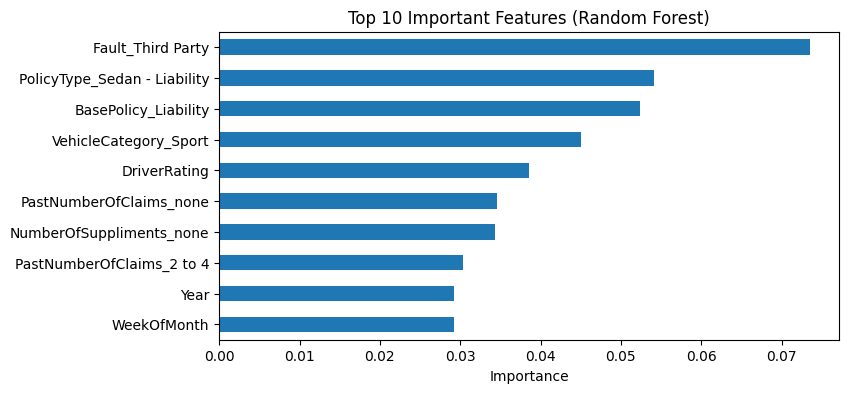

In [ ]:
# Which features were most important?
importances = pd.Series(model_rf.feature_importances_, index=X.columns)
top10 = importances.sort_values(ascending=False).head(10)
print(top10)

plt.figure(figsize=(8, 4))
top10.sort_values().plot(kind="barh")
plt.title("Top 10 Important Features (Random Forest)")
plt.xlabel("Importance")
plt.show()

## Step 11: SVM (Support Vector Machine)
SVM draws the **best dividing line** between Genuine and Fraud claims.
- **Decision boundary** = the line (in many dimensions: a **hyperplane**) that separates the two classes. SVM chooses the one with the **widest gap** between classes.
- **Scaling is important:** SVM relies on distances, so big-number columns would distort the boundary.
- **C** = how strict SVM is. Large C → tries hard to classify every training point (risk of overfitting). Small C → allows some mistakes (smoother boundary). We use the default C = 1.
- **Kernel** = a trick to draw curved boundaries. Default is `rbf` (curved). `linear` would be a straight line.
- `probability=True` → lets SVM give probabilities (slower to train).

**Note:** SVM is the slowest model here. It can take a few minutes in Colab. Please wait.

In [ ]:
# Step 11: SVM
from sklearn.svm import SVC

model_svm = SVC(
    probability=True,
    random_state=42
)

model_svm.fit(X_train_smote, y_train_smote)

y_pred_svm = model_svm.predict(X_test_scaled)
y_prob_svm = model_svm.predict_proba(X_test_scaled)[:, 1]

## Step 12: Model Evaluation
Think of the confusion matrix first (Fraud = "positive"):

| | Predicted Genuine | Predicted Fraud |
|---|---|---|
| **Actually Genuine** | **True Negative (TN)** – genuine claim correctly passed | **False Positive (FP)** – genuine claim wrongly flagged as fraud (annoys honest customer) |
| **Actually Fraud** | **False Negative (FN)** – fraud missed (company loses money) | **True Positive (TP)** – fraud correctly caught |

Metrics:
- **Accuracy** = (TP + TN) / all → % of all predictions that are correct. Misleading with imbalance.
- **Precision** = TP / (TP + FP) → when the model says *Fraud*, how often is it really fraud?
- **Recall** = TP / (TP + FN) → of all real frauds, how many did we catch?
- **F1-score** = balance of precision and recall.
- **ROC-AUC** = how well the model **ranks** fraud claims above genuine ones. 1.0 = perfect, 0.5 = random guessing. It uses probabilities, not just 0/1 predictions.

In [ ]:
# Step 12: Model Evaluation
from sklearn.metrics import precision_score, roc_auc_score, confusion_matrix

# Logistic Regression
acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr)
rec_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
auc_lr = roc_auc_score(y_test, y_prob_lr)

# KNN
acc_knn = accuracy_score(y_test, y_pred_knn)
prec_knn = precision_score(y_test, y_pred_knn)
rec_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
auc_knn = roc_auc_score(y_test, y_prob_knn)

# Random Forest
acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf)
rec_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
auc_rf = roc_auc_score(y_test, y_prob_rf)

# SVM
acc_svm = accuracy_score(y_test, y_pred_svm)
prec_svm = precision_score(y_test, y_pred_svm)
rec_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)
auc_svm = roc_auc_score(y_test, y_prob_svm)

print("Metrics calculated for all 4 models")

Metrics calculated for all 4 models


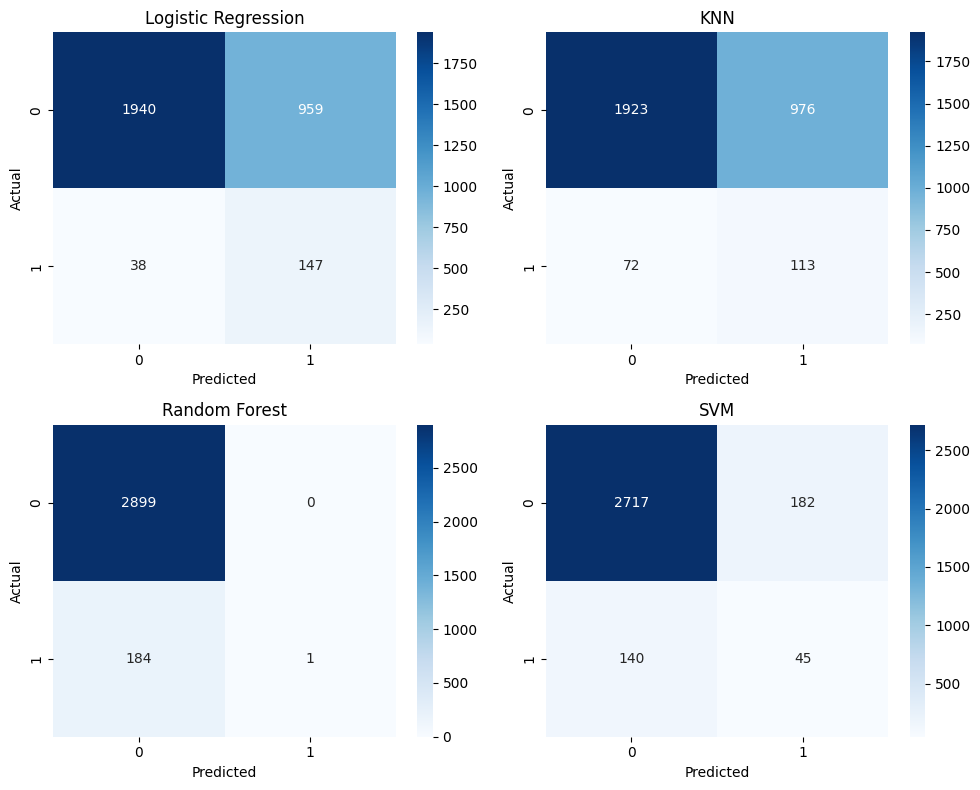

In [ ]:
# Confusion matrices
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_knn = confusion_matrix(y_test, y_pred_knn)
cm_rf = confusion_matrix(y_test, y_pred_rf)
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues")
plt.title("Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.subplot(2, 2, 2)
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Blues")
plt.title("KNN")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.subplot(2, 2, 3)
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.subplot(2, 2, 4)
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues")
plt.title("SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

**How to read each box:** top-left = TN, top-right = FP, bottom-left = FN, bottom-right = TP.
For fraud detection, look closely at the **bottom row**: bottom-left (frauds we missed) and bottom-right (frauds we caught).

In [ ]:
# Print TN, FP, FN, TP for each model
tn, fp, fn, tp = cm_lr.ravel()
print("Logistic Regression -> TN:", tn, "FP:", fp, "FN:", fn, "TP:", tp)

tn, fp, fn, tp = cm_knn.ravel()
print("KNN                 -> TN:", tn, "FP:", fp, "FN:", fn, "TP:", tp)

tn, fp, fn, tp = cm_rf.ravel()
print("Random Forest       -> TN:", tn, "FP:", fp, "FN:", fn, "TP:", tp)

tn, fp, fn, tp = cm_svm.ravel()
print("SVM                 -> TN:", tn, "FP:", fp, "FN:", fn, "TP:", tp)

Logistic Regression -> TN: 1940 FP: 959 FN: 38 TP: 147
KNN                 -> TN: 1923 FP: 976 FN: 72 TP: 113
Random Forest       -> TN: 2899 FP: 0 FN: 184 TP: 1
SVM                 -> TN: 2717 FP: 182 FN: 140 TP: 45


## Step 13: Compare the Models
We put all results in one table and one graph. We do **not** assume any model is best. We read the real results.
For fraud detection, **Recall, F1 and ROC-AUC matter more than Accuracy.**

In [ ]:
# Step 13: Model Comparison
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN", "Random Forest", "SVM"],
    "Accuracy": [acc_lr, acc_knn, acc_rf, acc_svm],
    "Precision": [prec_lr, prec_knn, prec_rf, prec_svm],
    "Recall": [rec_lr, rec_knn, rec_rf, rec_svm],
    "F1": [f1_lr, f1_knn, f1_rf, f1_svm],
    "ROC-AUC": [auc_lr, auc_knn, auc_rf, auc_svm]
})

comparison = comparison.round(4)
comparison

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.6767,0.1329,0.7946,0.2277,0.7957
1,KNN,0.6602,0.1038,0.6108,0.1774,0.6570
2,Random Forest,0.9403,1.0000,0.0054,0.0108,0.8144
3,SVM,0.8956,0.1982,0.2432,0.2184,0.7884


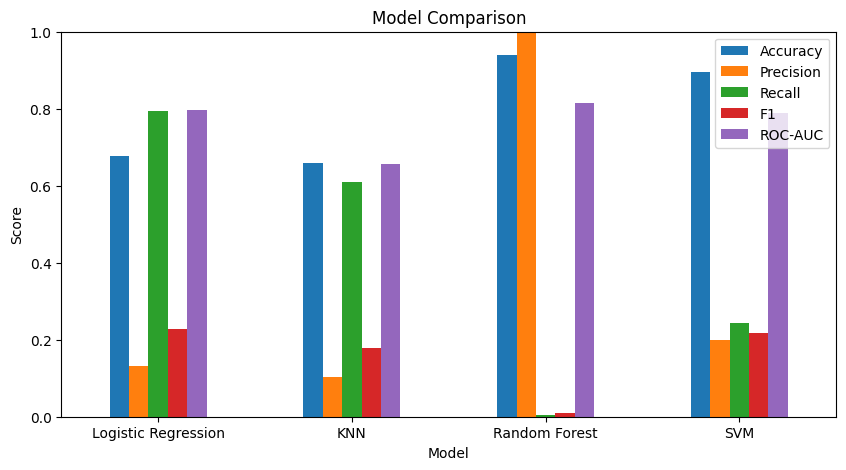

In [ ]:
# Comparison graph
comparison.set_index("Model").plot(kind="bar", figsize=(10, 5))
plt.title("Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="upper right")
plt.show()

In [ ]:
# Which model is best on each metric?
best_f1_model = comparison.loc[comparison["F1"].idxmax(), "Model"]
best_recall_model = comparison.loc[comparison["Recall"].idxmax(), "Model"]
best_auc_model = comparison.loc[comparison["ROC-AUC"].idxmax(), "Model"]
best_acc_model = comparison.loc[comparison["Accuracy"].idxmax(), "Model"]

print("Best Accuracy :", best_acc_model)
print("Best Recall   :", best_recall_model)
print("Best F1       :", best_f1_model)
print("Best ROC-AUC  :", best_auc_model)

Best Accuracy : Random Forest
Best Recall   : Logistic Regression
Best F1       : Logistic Regression
Best ROC-AUC  : Random Forest


## Step 14: Predict a New Claim
A new claim must go through the **same steps** as the training data:
1. Put the claim values in a dictionary → DataFrame (one row)
2. One-hot encode it (`drop_first=False` here, because with only 1 row, `drop_first=True` would remove every column)
3. `reindex(columns=X.columns, fill_value=0)` → make it have exactly the same 120 columns in the same order as training.
   Missing columns get 0; extra "first category" columns are discarded (which matches `drop_first=True` used in training)
4. Scale it with the **already fitted** `scaler.transform()` (never fit again!)
5. Give it to each model

Outputs:
- `predict()` → 0 or 1
- `predict_proba()` → `[Genuine probability, Fraud probability]`
- **Risk level** (our own simple rule): Fraud probability < 30% → Low, 30–60% → Medium, ≥ 60% → High

Note: models trained with SMOTE tend to give higher fraud probabilities than the real-world 6% rate. Treat the probability as a *risk score*.

In [ ]:
# Step 14: New Prediction

# 1. A new claim (change these values and run again to experiment)
new_claim = {
    "Month": "Jan",
    "WeekOfMonth": 3,
    "DayOfWeek": "Monday",
    "Make": "Honda",
    "AccidentArea": "Urban",
    "DayOfWeekClaimed": "Tuesday",
    "MonthClaimed": "Jan",
    "WeekOfMonthClaimed": 1,
    "Sex": "Male",
    "MaritalStatus": "Single",
    "Age": 30,
    "Fault": "Policy Holder",
    "PolicyType": "Sport - Collision",
    "VehicleCategory": "Sport",
    "VehiclePrice": "more than 69000",
    "RepNumber": 5,
    "Deductible": 400,
    "DriverRating": 1,
    "Days_Policy_Accident": "more than 30",
    "Days_Policy_Claim": "more than 30",
    "PastNumberOfClaims": "2 to 4",
    "AgeOfVehicle": "7 years",
    "AgeOfPolicyHolder": "26 to 30",
    "PoliceReportFiled": "No",
    "WitnessPresent": "No",
    "AgentType": "External",
    "NumberOfSuppliments": "none",
    "AddressChange_Claim": "no change",
    "NumberOfCars": "1 vehicle",
    "Year": 1996,
    "BasePolicy": "Collision"
}

# 2. Convert to a DataFrame with one row
new_df = pd.DataFrame([new_claim])

# 3. One-hot encode
new_encoded = pd.get_dummies(new_df, columns=categorical_columns, dtype=int)

# 4. Make columns exactly the same as the training columns
new_encoded = new_encoded.reindex(columns=X.columns, fill_value=0)

# 5. Scale using the scaler fitted on training data
new_scaled = scaler.transform(new_encoded)

print("New claim shape:", new_scaled.shape)

New claim shape: (1, 120)


In [ ]:
# Predict with all 4 models
model_names = ["Logistic Regression", "KNN", "Random Forest", "SVM"]
all_models = [model_lr, model_knn, model_rf, model_svm]

for i in range(len(all_models)):
    model = all_models[i]

    prediction = model.predict(new_scaled)[0]
    probabilities = model.predict_proba(new_scaled)[0]

    genuine_prob = probabilities[0]
    fraud_prob = probabilities[1]

    if fraud_prob < 0.30:
        risk = "Low"
    elif fraud_prob < 0.60:
        risk = "Medium"
    else:
        risk = "High"

    if prediction == 1:
        label = "Potentially Fraudulent"
    else:
        label = "Genuine"

    print("Model:", model_names[i])
    print("  Prediction        :", label)
    print("  Fraud probability :", round(fraud_prob * 100, 2), "%")
    print("  Genuine probability:", round(genuine_prob * 100, 2), "%")
    print("  Risk level        :", risk)
    print()

Model: Logistic Regression
  Prediction        : Potentially Fraudulent
  Fraud probability : 78.61 %
  Genuine probability: 21.39 %
  Risk level        : High

Model: KNN
  Prediction        : Potentially Fraudulent
  Fraud probability : 100.0 %
  Genuine probability: 0.0 %
  Risk level        : High

Model: Random Forest
  Prediction        : Genuine
  Fraud probability : 35.0 %
  Genuine probability: 65.0 %
  Risk level        : Medium

Model: SVM
  Prediction        : Potentially Fraudulent
  Fraud probability : 23.18 %
  Genuine probability: 76.82 %
  Risk level        : Low



## Step 15: Save the Trained Models
A **`.pkl` (pickle) file** stores a trained Python object on disk.
- **Why save?** Training (especially SVM) takes minutes. Once saved, we can load the model in a second.
- **Why not retrain for every prediction?** It would be slow and wasteful. Train once, reuse many times.
- The FastAPI backend will load these files with `joblib.load("file.pkl")` and call `predict()`.
- We must also save the **scaler** and the **column list**, because new claims need the exact same preprocessing.

In [ ]:
# Step 15: Save models
import joblib

joblib.dump(model_lr, "logistic_regression.pkl")
joblib.dump(model_knn, "knn.pkl")
joblib.dump(model_rf, "random_forest.pkl")
joblib.dump(model_svm, "svm.pkl")

joblib.dump(scaler, "scaler.pkl")
joblib.dump(X.columns.tolist(), "model_columns.pkl")
joblib.dump(categorical_columns, "categorical_columns.pkl")

print("All files saved!")

All files saved!


In [ ]:
# Test: load one model back and use it
loaded_model = joblib.load("random_forest.pkl")
print("Loaded model prediction:", loaded_model.predict(new_scaled)[0])

Loaded model prediction: 0


In [ ]:
# Download the files from Colab to your computer (works only in Google Colab)
from google.colab import files

files.download("logistic_regression.pkl")
files.download("knn.pkl")
files.download("random_forest.pkl")
files.download("svm.pkl")
files.download("scaler.pkl")
files.download("model_columns.pkl")
files.download("categorical_columns.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Viva Preparation (short answers)

**Dataset:** Vehicle insurance claims, 15,420 rows, 33 columns, from Kaggle (`fraud_oracle.csv`).
**Features:** Input columns such as age, fault, policy type, vehicle category, past claims, police report.
**Target variable:** `FraudFound_P` (0 = genuine, 1 = fraud).
**Classification:** Predicting a category (genuine or fraud) instead of a number.

**Logistic Regression:** A classification model that converts a weighted sum of features into a probability between 0 and 1.
**KNN:** Looks at the K most similar training claims and takes a majority vote.
**Random Forest:** Many decision trees voting together; reduces the errors of a single tree.
**SVM:** Finds the boundary (hyperplane) that separates the classes with the widest gap.
**Why these four models:** They are different types (linear, distance-based, tree-based, boundary-based), which allows a good comparison.

**Train/test split:** Training data teaches the model, test data checks it on unseen claims (80/20, random_state=42, stratified).
**Encoding:** Converting text categories to numbers.
**One-hot encoding:** One 0/1 column per category; avoids a fake order between categories.
**Scaling / StandardScaler:** Puts features on a similar scale: (value − mean) / std.
**Why KNN needs scaling:** It uses distance, so large-valued features would dominate.
**Why SVM needs scaling:** It also depends on distances, so large-valued features distort the boundary.
**Why the dataset is imbalanced:** Real fraud is rare; only about 6% of claims are fraud.
**SMOTE:** Creates new synthetic fraud examples between existing ones; applied only to training data.
**Data leakage:** Test information leaking into training. Avoided by splitting first, and fitting scaler and SMOTE on training data only.

**Accuracy:** % of all predictions that are correct.
**Precision:** When the model says fraud, how often is it right?
**Recall:** Of all real frauds, how many did we catch?
**F1-score:** Balance between precision and recall.
**ROC-AUC:** How well the model ranks fraud above genuine; 1 = perfect, 0.5 = random.
**Confusion matrix:** Table of correct and wrong predictions of each type.
**True Positive:** Fraud correctly detected. **True Negative:** Genuine correctly passed.
**False Positive:** Genuine claim wrongly flagged as fraud. **False Negative:** Fraud that was missed.
**Why accuracy alone is not enough:** Predicting "genuine" for everything gives ~94% accuracy but catches no fraud.
**Which model performed best:** Check the Step 13 table; justify with Recall, F1 and ROC-AUC, not accuracy alone.

**Why we save trained models:** Training is slow; saving lets us reuse the model instantly.
**Why FastAPI:** A fast, simple Python framework for building APIs; it can load the saved models directly.
**Why SQLite:** A lightweight database stored in a single file; no server setup, ideal for storing prediction history in a project.

In [ ]:
import sklearn; print(sklearn.__version__)

1.6.1
